In [3]:
%pip install sqlalchemy python-dotenv pyodbc matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached pyodbc-5.3.0-cp314-cp314-win_amd64.whl.metadata (2.8 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 296.7 kB/s eta 0:00:07
   -------- ------------------------------- 0.5/2.4 MB 296.7 kB/s eta 0:00:07
   -------- ------------------------------- 0.5/2.4 MB 296.7 kB/s eta 0:0


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:


import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import text
from dotenv import load_dotenv

print("=" * 55)
print("RED SALUD INTEGRAL CARAZO")
print("COMPARACIÓN DE MODELOS PREDICTIVOS")
print("=" * 55)

print("Bibliotecas importadas correctamente.")


RED SALUD INTEGRAL CARAZO
COMPARACIÓN DE MODELOS PREDICTIVOS
Bibliotecas importadas correctamente.


In [1]:
# ==================================================
# RECUPERAR CONEXIÓN CON SQL SERVER
# ==================================================

import sys
from pathlib import Path

import pandas as pd
from sqlalchemy import text
from dotenv import load_dotenv

# Carpeta principal del proyecto
RUTA_PROYECTO = Path.cwd()

# Cargar configuración del proyecto
load_dotenv(RUTA_PROYECTO / ".env")

# Localizar el archivo database.py
RUTA_SRC = RUTA_PROYECTO / "src"

if str(RUTA_SRC) not in sys.path:
    sys.path.insert(0, str(RUTA_SRC))

# Importar conexión original
from database import engine_sqlserver

# Conectar con SQL Server
engine = engine_sqlserver()

with engine.connect() as conexion:
    nombre_bd = conexion.execute(
        text("SELECT DB_NAME()")
    ).scalar_one()

print("Conexión establecida correctamente.")
print("Base de datos:", nombre_bd)


Conexión establecida correctamente.
Base de datos: RedSaludCarazoDW_V2


In [6]:

# ==================================================
# CARGA DEL DATASET PREDICTIVO
# ==================================================

consulta = text("""
    SELECT *
    FROM dbo.dm_dataset_prediccion
""")

with engine.connect() as conexion:
    df = pd.read_sql_query(
        consulta,
        conexion
    )

print("DATOS CARGADOS DESDE SQL SERVER")

print("Registros:", len(df))
print("Columnas:", len(df.columns))

# Mostrar los primeros cinco registros
display(df.head())


DATOS CARGADOS DESDE SQL SERVER
Registros: 8996
Columnas: 13


,id_cita,fecha_cita,anio,mes,centro_salud,especialidad,canal_agendamiento,grupo_edad,tipo_cobertura,espera_dias,citas_previas_perdidas,recordatorios_enviados,no_asistio
0,RSV2-000001,2026-04-09,2026,4,DIRIAMBA,MEDICINA GENERAL,WEB,60+,MIXTA,33,1,3,0
1,RSV2-000002,2026-04-30,2026,4,JINOTEPE,LABORATORIO,VENTANILLA,45-59,PRIVADA,6,4,3,1
2,RSV2-000004,2026-03-28,2026,3,DIRIAMBA,GINECOLOGÍA,WEB,30-44,PRIVADA,11,0,1,0
3,RSV2-000006,2026-01-06,2026,1,JINOTEPE,LABORATORIO,CALL CENTER,60+,PÚBLICA,35,4,2,1
4,RSV2-000007,2026-04-27,2026,4,SAN MARCOS,LABORATORIO,VENTANILLA,30-44,PÚBLICA,12,1,0,0


In [7]:

# ==================================================
# PASO 5. PREPARACIÓN DE VARIABLES
# ==================================================

OBJETIVO = "no_asistio"

# Variables numéricas
NUM = [
    "espera_dias",
    "citas_previas_perdidas"
]

# Variables categóricas
CAT = [
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura",
    "mes"
]

# Todas las variables predictoras
FEATURES = NUM + CAT

# Verificar columnas necesarias
columnas_necesarias = (
    FEATURES + [OBJETIVO, "fecha_cita"]
)

faltantes = set(columnas_necesarias) - set(df.columns)

if faltantes:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes)}"
    )

# Preparar copia del dataset
df_modelo = df.copy()

# Convertir fechas
df_modelo["fecha_cita"] = pd.to_datetime(
    df_modelo["fecha_cita"],
    errors="coerce"
)

if df_modelo["fecha_cita"].isna().any():
    raise ValueError(
        "Existen fechas inválidas en el dataset."
    )

# Preparar variable objetivo
df_modelo[OBJETIVO] = pd.to_numeric(
    df_modelo[OBJETIVO],
    errors="coerce"
)

# Conservar las clases conocidas
df_modelo = df_modelo[
    df_modelo[OBJETIVO].isin([0, 1])
].copy()

df_modelo[OBJETIVO] = (
    df_modelo[OBJETIVO].astype(int)
)

# Preparar variables numéricas
for columna in NUM:
    df_modelo[columna] = pd.to_numeric(
        df_modelo[columna],
        errors="coerce"
    )

# Preparar el mes como variable categórica
df_modelo["mes"] = (
    df_modelo["mes"].astype(str)
)

print("VARIABLES PREPARADAS CORRECTAMENTE")
print("Registros disponibles:", len(df_modelo))

print("\nDistribución de la variable objetivo:")
print(df_modelo[OBJETIVO].value_counts())

print("\nTasa de inasistencia:")
print(f"{df_modelo[OBJETIVO].mean() * 100:.2f}%")


VARIABLES PREPARADAS CORRECTAMENTE
Registros disponibles: 8996

Distribución de la variable objetivo:
no_asistio
0    5615
1    3381
Name: count, dtype: int64

Tasa de inasistencia:
37.58%


In [8]:

# ==================================================
# PASO 6. PARTICIÓN TEMPORAL DE LOS DATOS
# ==================================================

# Entrenamiento: enero a abril de 2026
train = df_modelo[
    (df_modelo["fecha_cita"] >= "2026-01-01")
    &
    (df_modelo["fecha_cita"] < "2026-05-01")
].copy()

# Validación: mayo de 2026
val = df_modelo[
    (df_modelo["fecha_cita"] >= "2026-05-01")
    &
    (df_modelo["fecha_cita"] < "2026-06-01")
].copy()

# Prueba final: junio de 2026
test = df_modelo[
    (df_modelo["fecha_cita"] >= "2026-06-01")
    &
    (df_modelo["fecha_cita"] < "2026-07-01")
].copy()

print("=" * 55)
print("PARTICIÓN TEMPORAL DEL DATASET")
print("=" * 55)

print("Entrenamiento:", len(train), "registros")
print("Validación:", len(val), "registros")
print("Prueba final:", len(test), "registros")

total = len(train) + len(val) + len(test)

print("\nTotal de registros:", total)

# Verificar que los conjuntos sean adecuados
for nombre, datos in [
    ("Entrenamiento", train),
    ("Validación", val),
    ("Prueba", test)
]:
    if datos.empty:
        raise ValueError(
            f"El conjunto {nombre} está vacío."
        )

    if datos[OBJETIVO].nunique() != 2:
        raise ValueError(
            f"El conjunto {nombre} no contiene ambas clases."
        )

if total != len(df_modelo):
    raise ValueError(
        "Hay registros fuera de los períodos definidos."
    )

print("\nPartición verificada correctamente.")


PARTICIÓN TEMPORAL DEL DATASET
Entrenamiento: 5948 registros
Validación: 1511 registros
Prueba final: 1537 registros

Total de registros: 8996

Partición verificada correctamente.


In [10]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scip


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:

# ==================================================
# PASO 7.1. IMPORTAR HERRAMIENTAS DE MINERÍA DE DATOS
# ==================================================

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Herramientas de minería de datos importadas correctamente.")


Herramientas de minería de datos importadas correctamente.


In [12]:

# ==================================================
# PASO 7.2. PREPROCESAMIENTO DE VARIABLES
# ==================================================

def crear_preprocesador(escalar=False):

    # Preparar variables numéricas
    pasos_numericos = [
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]

    # Algunos modelos necesitan escalado
    if escalar:
        pasos_numericos.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    numericas = Pipeline(
        pasos_numericos
    )

    # Preparar variables categóricas
    categoricas = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    # Integrar ambos tipos de variables
    preprocesador = ColumnTransformer([
        (
            "num",
            numericas,
            NUM
        ),
        (
            "cat",
            categoricas,
            CAT
        )
    ])

    return preprocesador


print("Función de preprocesamiento creada correctamente.")


Función de preprocesamiento creada correctamente.


In [13]:

# ==================================================
# PASO 7.3. CONFIGURACIÓN DE LOS SIETE MODELOS
# ==================================================

def crear_modelos():

    modelos = {

        # 1. REGRESIÓN LOGÍSTICA
        "Regresión Logística": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=True)
            ),
            (
                "clasificar",
                LogisticRegression(
                    max_iter=2000,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ]),

        # 2. ÁRBOL DE DECISIÓN
        "Árbol de Decisión": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=False)
            ),
            (
                "clasificar",
                DecisionTreeClassifier(
                    max_depth=8,
                    min_samples_split=20,
                    min_samples_leaf=10,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ]),

        # 3. RANDOM FOREST
        "Random Forest": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=False)
            ),
            (
                "clasificar",
                RandomForestClassifier(
                    n_estimators=300,
                    max_depth=4,
                    min_samples_leaf=10,
                    max_features="sqrt",
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]),

        # 4. GRADIENT BOOSTING
        "Gradient Boosting": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=False)
            ),
            (
                "clasificar",
                GradientBoostingClassifier(
                    n_estimators=200,
                    learning_rate=0.05,
                    max_depth=3,
                    random_state=42
                )
            )
        ]),

        # 5. KNN
        "KNN (k=10)": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=True)
            ),
            (
                "clasificar",
                KNeighborsClassifier(
                    n_neighbors=10,
                    weights="distance",
                    n_jobs=-1
                )
            )
        ]),

        # 6. NAIVE BAYES
        "Naive Bayes": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=False)
            ),
            (
                "clasificar",
                GaussianNB()
            )
        ]),

        # 7. SVM
        "SVM (RBF)": Pipeline([
            (
                "preparar",
                crear_preprocesador(escalar=True)
            ),
            (
                "clasificar",
                SVC(
                    kernel="rbf",
                    probability=True,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ])
    }

    return modelos


# Crear los modelos
modelos = crear_modelos()

print("=" * 55)
print("MODELOS CONFIGURADOS")
print("=" * 55)

for numero, nombre in enumerate(modelos, start=1):
    print(f"{numero}. {nombre}")

print("\nTotal de modelos:", len(modelos))


MODELOS CONFIGURADOS
1. Regresión Logística
2. Árbol de Decisión
3. Random Forest
4. Gradient Boosting
5. KNN (k=10)
6. Naive Bayes
7. SVM (RBF)

Total de modelos: 7


In [14]:

# ==================================================
# PASO 8.1. PREPARAR ENTRENAMIENTO Y VALIDACIÓN
# ==================================================

# Variables predictoras y objetivo
X_train = train[FEATURES]
y_train = train[OBJETIVO]

X_val = val[FEATURES]
y_val = val[OBJETIVO]

# Umbral de clasificación del proyecto
UMBRAL = 0.50

print("=" * 60)
print("PREPARACIÓN DEL ENTRENAMIENTO")
print("=" * 60)

print("Registros de entrenamiento:", len(X_train))
print("Registros de validación:", len(X_val))
print("Variables predictoras:", len(FEATURES))

print("\nVariables utilizadas:")
for variable in FEATURES:
    print("-", variable)

print("\nDatos preparados correctamente.")


PREPARACIÓN DEL ENTRENAMIENTO
Registros de entrenamiento: 5948
Registros de validación: 1511
Variables predictoras: 8

Variables utilizadas:
- espera_dias
- citas_previas_perdidas
- centro_salud
- especialidad
- canal_agendamiento
- grupo_edad
- tipo_cobertura
- mes

Datos preparados correctamente.


In [16]:

# ==================================================
# CONTROL OBLIGATORIO ANTES DE ENTRENAR LOS MODELOS
# ==================================================

ANIO_MODELO = 2026

control = verificar_periodo_mineria(
    ANIO_MODELO
)

if not control["apto"]:
    raise RuntimeError(
        "ENTRENAMIENTO DETENIDO: "
        "el período solicitado no superó "
        "las comprobaciones esenciales de calidad."
    )

print("\nControl de calidad superado.")
print("Se autoriza continuar con el entrenamiento.")


CONTROL DE CALIDAD ANTES DEL ENTRENAMIENTO

Año solicitado: 2026
Registros disponibles: 8996

PARTICIÓN TEMPORAL
Entrenamiento: 5948
Validación: 1511
Prueba: 1537

ESTADO: APTO PARA ENTRENAMIENTO
Las comprobaciones esenciales se superaron.

Control de calidad superado.
Se autoriza continuar con el entrenamiento.


In [15]:

# ==================================================
# PASO 8.2. ENTRENAMIENTO Y COMPARACIÓN DE MODELOS
# ==================================================

import time

resultados_comparacion = []
modelos_entrenados = {}

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("ENTRENAMIENTO Y COMPARACIÓN DE SIETE MODELOS")
print("=" * 70)

for nombre, modelo in modelos.items():

    print(f"\nEntrenando: {nombre}")

    inicio = time.time()

    # 1. Entrenar con enero-abril
    modelo.fit(X_train, y_train)

    # 2. Obtener probabilidades para mayo
    clases = list(modelo.classes_)

    indice_positivo = clases.index(1)

    probabilidades = modelo.predict_proba(
        X_val
    )[:, indice_positivo]

    # 3. Aplicar umbral de clasificación
    predicciones = (
        probabilidades >= UMBRAL
    ).astype(int)

    # 4. Calcular métricas
    accuracy = accuracy_score(
        y_val, predicciones
    )

    precision = precision_score(
        y_val, predicciones,
        zero_division=0
    )

    recall = recall_score(
        y_val, predicciones,
        zero_division=0
    )

    f1 = f1_score(
        y_val, predicciones,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val, predicciones,
        beta=2,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_val, probabilidades
    )

    pr_auc = average_precision_score(
        y_val, probabilidades
    )

    tiempo = time.time() - inicio

    # 5. Guardar resultados
    resultados_comparacion.append({
        "Modelo": nombre,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-Score (%)": f1 * 100,
        "F2-Score (%)": f2 * 100,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Tiempo (s)": tiempo
    })

    modelos_entrenados[nombre] = modelo

    print("Entrenamiento completado.")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Recall: {recall * 100:.2f}%")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Tiempo: {tiempo:.2f} segundos")

print("\n" + "=" * 70)
print("LOS SIETE MODELOS FUERON EVALUADOS")
print("=" * 70)


RED SALUD INTEGRAL CARAZO
ENTRENAMIENTO Y COMPARACIÓN DE SIETE MODELOS

Entrenando: Regresión Logística
Entrenamiento completado.
Accuracy: 79.75%
Recall: 80.18%
ROC-AUC: 0.8777
Tiempo: 0.34 segundos

Entrenando: Árbol de Decisión
Entrenamiento completado.
Accuracy: 80.08%
Recall: 79.82%
ROC-AUC: 0.8672
Tiempo: 0.16 segundos

Entrenando: Random Forest
Entrenamiento completado.
Accuracy: 84.45%
Recall: 70.89%
ROC-AUC: 0.8841
Tiempo: 2.04 segundos

Entrenando: Gradient Boosting
Entrenamiento completado.
Accuracy: 84.32%
Recall: 70.89%
ROC-AUC: 0.8854
Tiempo: 2.98 segundos

Entrenando: KNN (k=10)
Entrenamiento completado.
Accuracy: 79.15%
Recall: 65.18%
ROC-AUC: 0.8402
Tiempo: 0.36 segundos

Entrenando: Naive Bayes
Entrenamiento completado.
Accuracy: 81.01%
Recall: 68.57%
ROC-AUC: 0.8619
Tiempo: 0.14 segundos

Entrenando: SVM (RBF)


C:\Users\Usuario\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Entrenamiento completado.
Accuracy: 82.93%
Recall: 72.50%
ROC-AUC: 0.8746
Tiempo: 17.66 segundos

LOS SIETE MODELOS FUERON EVALUADOS


In [16]:

# ==================================================
# PASO 8.3. TABLA COMPARATIVA DE LOS SIETE MODELOS
# ==================================================

# Construir tabla
tabla_comparativa = pd.DataFrame(
    resultados_comparacion
)

# Ordenar desde el mejor ROC-AUC
tabla_comparativa = (
    tabla_comparativa
    .sort_values(
        by="ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

# Mostrar valores redondeados
print("=" * 70)
print("TABLA COMPARATIVA - VALIDACIÓN MAYO")
print("=" * 70)

display(
    tabla_comparativa.round(4)
)

# Seleccionar el mejor modelo según ROC-AUC
mejor_nombre = tabla_comparativa.iloc[0]["Modelo"]

mejor_roc_auc = tabla_comparativa.iloc[0]["ROC-AUC"]

mejor_modelo = modelos_entrenados[
    mejor_nombre
]

print("\n" + "=" * 70)
print("MODELO SELECCIONADO")
print("=" * 70)

print("Modelo:", mejor_nombre)
print(f"ROC-AUC de validación: {mejor_roc_auc:.4f}")

print("\nCriterio utilizado:")
print("Mayor ROC-AUC en el conjunto de mayo.")


TABLA COMPARATIVA - VALIDACIÓN MAYO


,Modelo,Accuracy (%),Precision (%),Recall (%),F1-Score (%),F2-Score (%),ROC-AUC,PR-AUC,Tiempo (s)
0,Gradient Boosting,84.3150,84.2887,70.8929,77.0126,73.2202,0.8854,0.8411,2.9796
1,Random Forest,84.4474,84.6482,70.8929,77.1623,73.2743,0.8841,0.8371,2.0379
2,Regresión Logística,79.7485,69.7205,80.1786,74.5847,77.8433,0.8777,0.8309,0.3382
3,SVM (RBF),82.9252,79.6078,72.5000,75.8879,73.8182,0.8746,0.8203,17.6640
4,Árbol de Decisión,80.0794,70.3937,79.8214,74.8117,77.7391,0.8672,0.8154,0.1603
5,Naive Bayes,81.0060,77.5758,68.5714,72.7962,70.2011,0.8619,0.8090,0.1418
6,KNN (k=10),79.1529,75.2577,65.1786,69.8565,66.9725,0.8402,0.7815,0.3554



MODELO SELECCIONADO
Modelo: Gradient Boosting
ROC-AUC de validación: 0.8854

Criterio utilizado:
Mayor ROC-AUC en el conjunto de mayo.


In [4]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.2. RECUPERACIÓN Y COMPARACIÓN DE SIETE MODELOS
# ============================================================

import sys
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from dotenv import load_dotenv
from sqlalchemy import text
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. LOCALIZAR PROYECTO Y CONEXIÓN
# ============================================================

proyecto = Path.cwd()

proyecto_anterior = (
    Path.home()
    / "Downloads"
    / "RedSaludCarazo_proyecto_base"
)

if not (proyecto_anterior / "src" / "database.py").is_file():
    raise FileNotFoundError(
        "No se encontró database.py del proyecto anterior."
    )

sys.path.insert(
    0,
    str(proyecto_anterior / "src")
)

load_dotenv(
    proyecto_anterior / ".env",
    override=True
)

from database import engine_sqlserver

engine = engine_sqlserver()


# ============================================================
# 2. CARGAR DATASET DESDE SQL SERVER
# ============================================================

with engine.connect() as conexion:

    base = conexion.execute(
        text("SELECT DB_NAME()")
    ).scalar_one()

    df = pd.read_sql_query(
        text("""
            SELECT *
            FROM dbo.dm_dataset_prediccion
        """),
        conexion
    )

if base != "RedSaludCarazoDW_V2":
    raise ValueError(
        f"Base de datos inesperada: {base}"
    )

print("Base de datos:", base)
print("Registros cargados:", len(df))


# ============================================================
# 3. CONFIGURAR VARIABLES DEL EXPERIMENTO ANTERIOR
# ============================================================

OBJETIVO = "no_asistio"

NUM = [
    "espera_dias",
    "citas_previas_perdidas"
]

CAT = [
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura",
    "mes"
]

FEATURES = NUM + CAT
UMBRAL = 0.50

requeridas = FEATURES + [
    OBJETIVO,
    "fecha_cita",
    "id_cita"
]

faltantes = set(requeridas) - set(df.columns)

if faltantes:
    raise ValueError(
        f"Columnas faltantes: {sorted(faltantes)}"
    )


# ============================================================
# 4. PREPARAR VARIABLES
# ============================================================

df["fecha_cita"] = pd.to_datetime(
    df["fecha_cita"],
    errors="coerce"
)

df[OBJETIVO] = pd.to_numeric(
    df[OBJETIVO],
    errors="coerce"
)

if df["fecha_cita"].isna().any():
    raise ValueError("Existen fechas inválidas.")

if not df[OBJETIVO].isin([0, 1]).all():
    raise ValueError("Existen valores objetivo inválidos.")

df[OBJETIVO] = df[OBJETIVO].astype(int)

for campo in NUM:
    df[campo] = pd.to_numeric(
        df[campo],
        errors="coerce"
    )

for campo in CAT:
    df[campo] = (
        df[campo]
        .astype("object")
        .where(df[campo].notna(), np.nan)
    )

df["mes"] = df["mes"].astype(str)

print("\nVARIABLES PREDICTORAS:")
print(FEATURES)


# ============================================================
# 5. DIVISIÓN CRONOLÓGICA
# ============================================================

train = df.loc[
    (df["fecha_cita"] >= "2026-01-01")
    & (df["fecha_cita"] < "2026-05-01")
].copy()

val = df.loc[
    (df["fecha_cita"] >= "2026-05-01")
    & (df["fecha_cita"] < "2026-06-01")
].copy()

test = df.loc[
    (df["fecha_cita"] >= "2026-06-01")
    & (df["fecha_cita"] < "2026-07-01")
].copy()

if len(train) + len(val) + len(test) != len(df):
    raise ValueError(
        "Existen registros fuera de los períodos definidos."
    )

for nombre, conjunto in [
    ("Entrenamiento", train),
    ("Validación", val),
    ("Prueba", test)
]:
    if conjunto.empty or conjunto[OBJETIVO].nunique() != 2:
        raise ValueError(f"Conjunto inválido: {nombre}")

    print(nombre, ":", len(conjunto))

X_train = train[FEATURES].copy()
y_train = train[OBJETIVO].copy()

X_val = val[FEATURES].copy()
y_val = val[OBJETIVO].copy()

# Junio permanece sin utilizar.
X_test = test[FEATURES].copy()
y_test = test[OBJETIVO].copy()


# ============================================================
# 6. PREPROCESAMIENTO
# ============================================================

def crear_preprocesador(escalar=False):

    pasos_num = [
        ("imputar", SimpleImputer(strategy="median"))
    ]

    if escalar:
        pasos_num.append(
            ("escalar", StandardScaler())
        )

    try:
        onehot = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        onehot = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    num_pipe = Pipeline(pasos_num)

    cat_pipe = Pipeline([
        (
            "imputar",
            SimpleImputer(strategy="most_frequent")
        ),
        ("onehot", onehot)
    ])

    return ColumnTransformer([
        ("numericas", num_pipe, NUM),
        ("categoricas", cat_pipe, CAT)
    ])


# ============================================================
# 7. DEFINIR LOS SIETE ALGORITMOS
# ============================================================

def crear_modelo(clasificador, escalar=False):

    return Pipeline([
        (
            "preparar",
            crear_preprocesador(escalar)
        ),
        ("clasificar", clasificador)
    ])


algoritmos = {

    "Regresión Logística": crear_modelo(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    ),

    "Árbol de Decisión": crear_modelo(
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": crear_modelo(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    ),

    "Gradient Boosting": crear_modelo(
        GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )
    ),

    "KNN (k=10)": crear_modelo(
        KNeighborsClassifier(
            n_neighbors=10,
            weights="distance",
            n_jobs=-1
        ),
        escalar=True
    ),

    "Naive Bayes": crear_modelo(
        GaussianNB()
    ),

    "SVM (RBF)": crear_modelo(
        SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        escalar=True
    )
}


# ============================================================
# 8. EVALUAR MODELOS EN MAYO
# ============================================================

resultados_comparacion = []
modelos_entrenados = {}

carpeta_modelos = (
    proyecto
    / "resultados"
    / "04_modelos"
    / "comparacion_siete"
)

carpeta_modelos.mkdir(
    parents=True,
    exist_ok=True
)

fecha = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ")

for nombre, modelo in algoritmos.items():

    print("\nEntrenando:", nombre)

    inicio = time.perf_counter()

    modelo.fit(
        X_train,
        y_train
    )

    probabilidades = modelo.predict_proba(
        X_val
    )[:, 1]

    pred = (
        probabilidades >= UMBRAL
    ).astype(int)

    vn, fp, fn, vp = confusion_matrix(
        y_val,
        pred,
        labels=[0, 1]
    ).ravel()

    metricas = {
        "Modelo": nombre,
        "Accuracy (%)": round(
            accuracy_score(y_val, pred) * 100, 4
        ),
        "Precision (%)": round(
            precision_score(y_val, pred, zero_division=0) * 100, 4
        ),
        "Recall (%)": round(
            recall_score(y_val, pred, zero_division=0) * 100, 4
        ),
        "F1 (%)": round(
            f1_score(y_val, pred, zero_division=0) * 100, 4
        ),
        "F2 (%)": round(
            fbeta_score(y_val, pred, beta=2, zero_division=0)
            * 100, 4
        ),
        "ROC-AUC": round(
            roc_auc_score(y_val, probabilidades), 4
        ),
        "PR-AUC": round(
            average_precision_score(
                y_val, probabilidades
            ), 4
        ),
        "VP": int(vp),
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),
        "Tiempo_s": round(
            time.perf_counter() - inicio,
            2
        )
    }

    resultados_comparacion.append(metricas)
    modelos_entrenados[nombre] = modelo

    # Guardar cada modelo entrenado.
    joblib.dump(
        modelo,
        carpeta_modelos / f"{nombre}_{fecha}.joblib"
    )

    print(
        "Accuracy:",
        f"{metricas['Accuracy (%)']:.2f}%"
    )

    print(
        "ROC-AUC:",
        f"{metricas['ROC-AUC']:.4f}"
    )


# ============================================================
# 9. TABLA DE COMPARACIÓN
# ============================================================

tabla_comparacion_7 = (
    pd.DataFrame(resultados_comparacion)
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("COMPARACIÓN DE SIETE MODELOS - MAYO 2026")
print("=" * 70)

display(tabla_comparacion_7)


# ============================================================
# 10. VERIFICACIONES
# ============================================================

assert len(resultados_comparacion) == 7
assert len(modelos_entrenados) == 7

assert set(
    tabla_comparacion_7["Modelo"]
) == set(modelos_entrenados.keys())

print("\nVERIFICACIONES")
print("Modelos entrenados:", len(modelos_entrenados))
print("Resultados disponibles:", len(resultados_comparacion))
print("Validación: mayo 2026")
print("Prueba de junio utilizada: NO")


# ============================================================
# 11. GUARDAR LA COMPARACIÓN
# ============================================================

ruta_comparacion = (
    carpeta_modelos
    / f"comparacion_siete_modelos_{fecha}.csv"
)

tabla_comparacion_7.to_csv(
    ruta_comparacion,
    index=False,
    encoding="utf-8-sig"
)

print("\nComparación guardada en:")
print(ruta_comparacion)

print("\nPASO 8.2 FINALIZADO")
print("Ya puedes ejecutar el PASO 8.3.")


Base de datos: RedSaludCarazoDW_V2
Registros cargados: 8996

VARIABLES PREDICTORAS:
['espera_dias', 'citas_previas_perdidas', 'centro_salud', 'especialidad', 'canal_agendamiento', 'grupo_edad', 'tipo_cobertura', 'mes']
Entrenamiento : 5948
Validación : 1511
Prueba : 1537

Entrenando: Regresión Logística
Accuracy: 79.75%
ROC-AUC: 0.8777

Entrenando: Árbol de Decisión
Accuracy: 80.08%
ROC-AUC: 0.8672

Entrenando: Random Forest
Accuracy: 84.45%
ROC-AUC: 0.8841

Entrenando: Gradient Boosting
Accuracy: 84.31%
ROC-AUC: 0.8854

Entrenando: KNN (k=10)
Accuracy: 79.15%
ROC-AUC: 0.8402

Entrenando: Naive Bayes
Accuracy: 81.01%
ROC-AUC: 0.8619

Entrenando: SVM (RBF)


C:\Users\Usuario\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 82.93%
ROC-AUC: 0.8746

COMPARACIÓN DE SIETE MODELOS - MAYO 2026


,Modelo,Accuracy (%),Precision (%),Recall (%),F1 (%),F2 (%),ROC-AUC,PR-AUC,VP,VN,FP,FN,Tiempo_s
0,Gradient Boosting,84.3150,84.2887,70.8929,77.0126,73.2202,0.8854,0.8411,397,877,74,163,2.14
1,Random Forest,84.4474,84.6482,70.8929,77.1623,73.2743,0.8841,0.8371,397,879,72,163,1.71
2,Regresión Logística,79.7485,69.7205,80.1786,74.5847,77.8433,0.8777,0.8309,449,756,195,111,0.36
3,SVM (RBF),82.9252,79.6078,72.5000,75.8879,73.8182,0.8746,0.8203,406,847,104,154,12.94
4,Árbol de Decisión,80.0794,70.3937,79.8214,74.8117,77.7391,0.8672,0.8154,447,763,188,113,0.19
5,Naive Bayes,81.0060,77.5758,68.5714,72.7962,70.2011,0.8619,0.8090,384,840,111,176,0.17
6,KNN (k=10),79.1529,75.2577,65.1786,69.8565,66.9725,0.8402,0.7815,365,831,120,195,0.34



VERIFICACIONES
Modelos entrenados: 7
Resultados disponibles: 7
Validación: mayo 2026
Prueba de junio utilizada: NO

Comparación guardada en:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\04_modelos\comparacion_siete\comparacion_siete_modelos_20261025T022238Z.csv

PASO 8.2 FINALIZADO
Ya puedes ejecutar el PASO 8.3.


In [5]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 8.3. COMPARACIÓN Y SELECCIÓN DE TRES MODELOS
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display


# ============================================================
# 1. CONSTRUIR TABLA COMPARATIVA
# ============================================================

tabla_comparativa = pd.DataFrame(
    resultados_comparacion
).copy()

# Identificar cómo están nombradas las columnas
# en los resultados de nuestro cuaderno.

def buscar_columna(opciones):

    for columna in opciones:
        if columna in tabla_comparativa.columns:
            return columna

    raise ValueError(
        f"No se encontró ninguna columna entre: {opciones}"
    )


col_roc = buscar_columna([
    "ROC-AUC",
    "ROC_AUC",
    "ROC AUC"
])

col_precision = buscar_columna([
    "Precisión (%)",
    "Precision (%)",
    "Precisión",
    "Precision"
])

col_recall = buscar_columna([
    "Recall (%)",
    "Recall"
])

# Verificar que las métricas sean numéricas
for columna in [
    col_roc,
    col_precision,
    col_recall
]:

    tabla_comparativa[columna] = pd.to_numeric(
        tabla_comparativa[columna],
        errors="raise"
    )

    if tabla_comparativa[columna].isna().any():
        raise ValueError(
            f"Existen valores nulos en {columna}."
        )

# Ordenar según ROC-AUC, como en el ejemplo original
tabla_comparativa = (
    tabla_comparativa
    .sort_values(
        by=col_roc,
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 2. MOSTRAR COMPARACIÓN GENERAL
# ============================================================

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("TABLA COMPARATIVA - VALIDACIÓN MAYO")
print("=" * 70)

display(
    tabla_comparativa.round(4)
)


# ============================================================
# 3. DEFINIR LOS TRES KPI PRINCIPALES
# ============================================================

criterios_seleccion = [
    {
        "Codigo": "KPI-M01",
        "KPI": "ROC-AUC",
        "Columna": col_roc,
        "Objetivo": (
            "Distinguir entre pacientes que "
            "asisten y no asisten"
        )
    },
    {
        "Codigo": "KPI-M02",
        "KPI": "Precision",
        "Columna": col_precision,
        "Objetivo": (
            "Obtener alertas de inasistencia "
            "con mayor precisión"
        )
    },
    {
        "Codigo": "KPI-M03",
        "KPI": "Recall",
        "Columna": col_recall,
        "Objetivo": (
            "Identificar la mayor cantidad "
            "de inasistencias reales"
        )
    }
]


# ============================================================
# 4. SELECCIONAR TRES MODELOS DIFERENTES
# ============================================================

# Para cada KPI buscamos el mejor algoritmo disponible.
#
# Si un modelo ya fue elegido para otro KPI,
# pasamos al siguiente de la clasificación.
#
# Así evitamos asignar el mismo algoritmo
# a dos indicadores diferentes.

modelos_seleccionados = {}

nombres_utilizados = set()

resultados_seleccion = []

for criterio in criterios_seleccion:

    columna = criterio["Columna"]

    clasificacion = (
        tabla_comparativa
        .sort_values(
            by=columna,
            ascending=False
        )
        .reset_index(drop=True)
    )

    mejor_individual = clasificacion.iloc[0]

    disponibles = clasificacion.loc[
        ~clasificacion["Modelo"].isin(
            nombres_utilizados
        )
    ]

    if disponibles.empty:
        raise ValueError(
            "No hay suficientes modelos distintos "
            "para seleccionar tres."
        )

    elegido = disponibles.iloc[0]

    nombre = elegido["Modelo"]

    if nombre not in modelos_entrenados:
        raise KeyError(
            f"El modelo '{nombre}' no aparece "
            "en el diccionario modelos_entrenados."
        )

    # Guardar el modelo real entrenado
    modelos_seleccionados[
        criterio["KPI"]
    ] = modelos_entrenados[nombre]

    nombres_utilizados.add(nombre)

    resultados_seleccion.append({
        "Codigo": criterio["Codigo"],
        "KPI": criterio["KPI"],
        "Modelo_seleccionado": nombre,
        "Resultado_KPI": float(
            elegido[columna]
        ),
        "Mejor_resultado_individual": float(
            mejor_individual[columna]
        ),
        "Objetivo": criterio["Objetivo"]
    })


# ============================================================
# 5. CONSTRUIR TABLA DE SELECCIÓN
# ============================================================

tabla_tres_modelos = pd.DataFrame(
    resultados_seleccion
)

tabla_tres_modelos["Diferencia"] = (
    tabla_tres_modelos[
        "Mejor_resultado_individual"
    ]
    -
    tabla_tres_modelos[
        "Resultado_KPI"
    ]
).round(4)

print("\n" + "=" * 70)
print("TRES MODELOS SELECCIONADOS")
print("=" * 70)

display(
    tabla_tres_modelos[
        [
            "Codigo",
            "KPI",
            "Modelo_seleccionado",
            "Resultado_KPI",
            "Mejor_resultado_individual",
            "Diferencia"
        ]
    ].round(4)
)


# ============================================================
# 6. MOSTRAR JUSTIFICACIÓN DE LA SELECCIÓN
# ============================================================

print("\n" + "=" * 70)
print("JUSTIFICACIÓN DE LOS MODELOS")
print("=" * 70)

for fila in tabla_tres_modelos.itertuples():

    print("\n" + "-" * 60)

    print("KPI:", fila.KPI)

    print(
        "Modelo seleccionado:",
        fila.Modelo_seleccionado
    )

    if fila.KPI == "ROC-AUC":

        print(
            f"ROC-AUC de validación: "
            f"{fila.Resultado_KPI:.4f}"
        )

    else:

        print(
            f"Resultado de validación: "
            f"{fila.Resultado_KPI:.2f}"
        )

    print("Objetivo:", fila.Objetivo)

    if fila.Diferencia > 0:

        print(
            "Nota: no es el máximo individual "
            "de este KPI, porque se requieren "
            "tres modelos distintos."
        )

    else:

        print(
            "El modelo obtuvo el mejor resultado "
            "individual en este KPI."
        )


# ============================================================
# 7. VERIFICACIONES
# ============================================================

assert len(tabla_tres_modelos) == 3

assert (
    tabla_tres_modelos[
        "Modelo_seleccionado"
    ].nunique() == 3
)

assert set(
    tabla_tres_modelos["KPI"]
) == {
    "ROC-AUC",
    "Precision",
    "Recall"
}

print("\n" + "=" * 70)
print("VERIFICACIÓN DE SELECCIÓN")
print("=" * 70)

print("Modelos seleccionados: 3")
print("Modelos diferentes: 3")
print("KPI principales: 3")
print("Criterio: rendimiento en validación de mayo")
print("Datos de prueba de junio utilizados: NO")


# ============================================================
# 8. GUARDAR EVIDENCIAS
# ============================================================

carpeta_seleccion = (
    Path(proyecto)
    / "resultados"
    / "05_kpi"
)

carpeta_seleccion.mkdir(
    parents=True,
    exist_ok=True
)

tabla_comparativa.to_csv(
    carpeta_seleccion
    / "comparacion_siete_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_tres_modelos.to_csv(
    carpeta_seleccion
    / "tres_modelos_seleccionados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nEVIDENCIAS GUARDADAS")
print("comparacion_siete_modelos.csv")
print("tres_modelos_seleccionados.csv")

print("\nPASO 8.3 FINALIZADO")


RED SALUD INTEGRAL CARAZO
TABLA COMPARATIVA - VALIDACIÓN MAYO


,Modelo,Accuracy (%),Precision (%),Recall (%),F1 (%),F2 (%),ROC-AUC,PR-AUC,VP,VN,FP,FN,Tiempo_s
0,Gradient Boosting,84.3150,84.2887,70.8929,77.0126,73.2202,0.8854,0.8411,397,877,74,163,2.14
1,Random Forest,84.4474,84.6482,70.8929,77.1623,73.2743,0.8841,0.8371,397,879,72,163,1.71
2,Regresión Logística,79.7485,69.7205,80.1786,74.5847,77.8433,0.8777,0.8309,449,756,195,111,0.36
3,SVM (RBF),82.9252,79.6078,72.5000,75.8879,73.8182,0.8746,0.8203,406,847,104,154,12.94
4,Árbol de Decisión,80.0794,70.3937,79.8214,74.8117,77.7391,0.8672,0.8154,447,763,188,113,0.19
5,Naive Bayes,81.0060,77.5758,68.5714,72.7962,70.2011,0.8619,0.8090,384,840,111,176,0.17
6,KNN (k=10),79.1529,75.2577,65.1786,69.8565,66.9725,0.8402,0.7815,365,831,120,195,0.34



TRES MODELOS SELECCIONADOS


,Codigo,KPI,Modelo_seleccionado,Resultado_KPI,Mejor_resultado_individual,Diferencia
0,KPI-M01,ROC-AUC,Gradient Boosting,0.8854,0.8854,0.0
1,KPI-M02,Precision,Random Forest,84.6482,84.6482,0.0
2,KPI-M03,Recall,Regresión Logística,80.1786,80.1786,0.0



JUSTIFICACIÓN DE LOS MODELOS

------------------------------------------------------------
KPI: ROC-AUC
Modelo seleccionado: Gradient Boosting
ROC-AUC de validación: 0.8854
Objetivo: Distinguir entre pacientes que asisten y no asisten
El modelo obtuvo el mejor resultado individual en este KPI.

------------------------------------------------------------
KPI: Precision
Modelo seleccionado: Random Forest
Resultado de validación: 84.65
Objetivo: Obtener alertas de inasistencia con mayor precisión
El modelo obtuvo el mejor resultado individual en este KPI.

------------------------------------------------------------
KPI: Recall
Modelo seleccionado: Regresión Logística
Resultado de validación: 80.18
Objetivo: Identificar la mayor cantidad de inasistencias reales
El modelo obtuvo el mejor resultado individual en este KPI.

VERIFICACIÓN DE SELECCIÓN
Modelos seleccionados: 3
Modelos diferentes: 3
KPI principales: 3
Criterio: rendimiento en validación de mayo
Datos de prueba de junio utiliza

In [17]:

# ==================================================
# PASO 9.1. PRUEBA FINAL DEL MODELO SELECCIONADO
# ==================================================

print("=" * 65)
print("EVALUACIÓN FINAL DE GRADIENT BOOSTING")
print("=" * 65)

# Preparar datos de prueba de junio
X_test = test[FEATURES]
y_test = test[OBJETIVO]

print("Modelo seleccionado:", mejor_nombre)
print("Registros de prueba:", len(X_test))
print("Umbral utilizado:", UMBRAL)

# Usar el modelo entrenado y seleccionado en mayo
modelo_final = mejor_modelo

# Obtener probabilidades reales del modelo
clases = list(modelo_final.classes_)
indice_positivo = clases.index(1)

probabilidades_test = modelo_final.predict_proba(
    X_test
)[:, indice_positivo]

# Convertir probabilidades a clasificación
predicciones_test = (
    probabilidades_test >= UMBRAL
).astype(int)

print("\nPredicciones realizadas correctamente.")
print("Total de predicciones:", len(predicciones_test))


EVALUACIÓN FINAL DE GRADIENT BOOSTING
Modelo seleccionado: Gradient Boosting
Registros de prueba: 1537
Umbral utilizado: 0.5

Predicciones realizadas correctamente.
Total de predicciones: 1537


In [18]:

# ==================================================
# PASO 9.2. CÁLCULO DE MÉTRICAS DE GRADIENT BOOSTING
# ==================================================

# Calcular métricas
accuracy_final = accuracy_score(
    y_test, predicciones_test
)

precision_final = precision_score(
    y_test, predicciones_test,
    zero_division=0
)

recall_final = recall_score(
    y_test, predicciones_test,
    zero_division=0
)

f1_final = f1_score(
    y_test, predicciones_test,
    zero_division=0
)

f2_final = fbeta_score(
    y_test, predicciones_test,
    beta=2,
    zero_division=0
)

roc_auc_final = roc_auc_score(
    y_test, probabilidades_test
)

pr_auc_final = average_precision_score(
    y_test, probabilidades_test
)

# Calcular matriz de confusión
matriz = confusion_matrix(
    y_test,
    predicciones_test,
    labels=[0, 1]
)

vn, fp, fn, vp = matriz.ravel()

# Mostrar resultados
print("=" * 65)
print("RESULTADOS FINALES - GRADIENT BOOSTING")
print("=" * 65)

print("Citas evaluadas:", len(y_test))

print(f"\nAccuracy:  {accuracy_final * 100:.2f}%")
print(f"Precision: {precision_final * 100:.2f}%")
print(f"Recall:    {recall_final * 100:.2f}%")
print(f"F1-Score:  {f1_final * 100:.2f}%")
print(f"F2-Score:  {f2_final * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc_final:.4f}")
print(f"PR-AUC:    {pr_auc_final:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("Verdaderos positivos:", vp)
print("Verdaderos negativos:", vn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)

print("\nPredicciones correctas:", vp + vn)
print("Predicciones incorrectas:", fp + fn)


RESULTADOS FINALES - GRADIENT BOOSTING
Citas evaluadas: 1537

Accuracy:  83.15%
Precision: 80.16%
Recall:    71.76%
F1-Score:  75.73%
F2-Score:  73.29%
ROC-AUC:   0.8886
PR-AUC:    0.8280

MATRIZ DE CONFUSIÓN
Verdaderos positivos: 404
Verdaderos negativos: 874
Falsos positivos: 100
Falsos negativos: 159

Predicciones correctas: 1278
Predicciones incorrectas: 259


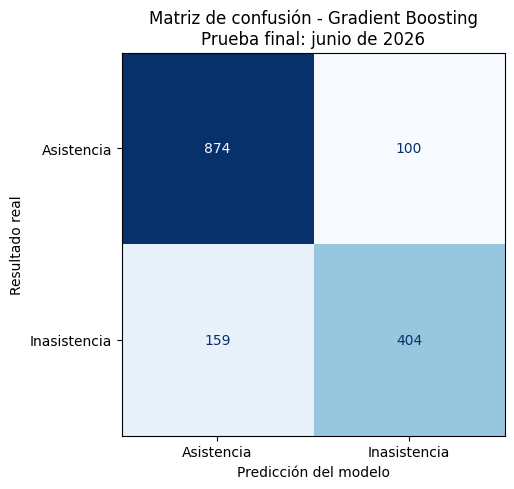

In [19]:

# ==================================================
# PASO 10.1. GRÁFICO DE MATRIZ DE CONFUSIÓN
# ==================================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Asistencia", "Inasistencia"]
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Matriz de confusión - Gradient Boosting\n"
    "Prueba final: junio de 2026"
)

ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Resultado real")

plt.tight_layout()
plt.show()


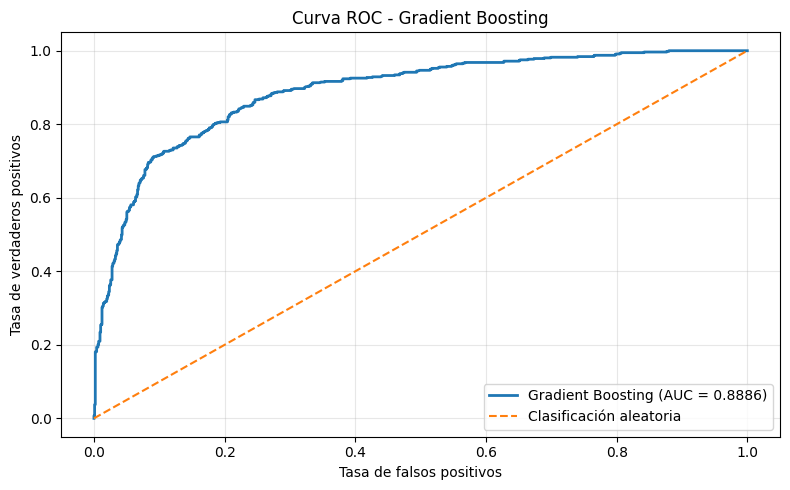

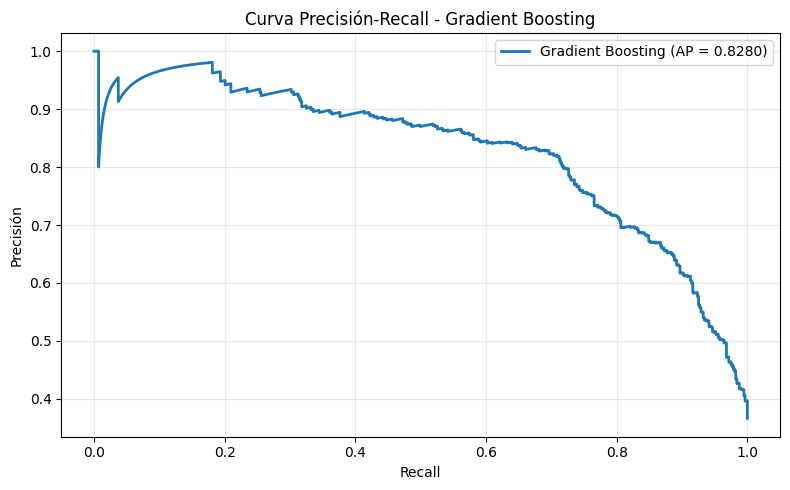

In [20]:

# ==================================================
# PASO 10.2. CURVA ROC
# ==================================================

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

# Obtener puntos de la curva ROC
fpr, tpr, umbrales_roc = roc_curve(
    y_test,
    probabilidades_test
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Gradient Boosting (AUC = {roc_auc_final:.4f})"
)

# Línea de referencia aleatoria
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificación aleatoria"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC - Gradient Boosting")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==================================================
# CURVA PRECISIÓN-RECALL
# ==================================================

precision_curva, recall_curva, _ = (
    precision_recall_curve(
        y_test,
        probabilidades_test
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_curva,
    precision_curva,
    linewidth=2,
    label=f"Gradient Boosting (AP = {pr_auc_final:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precisión")
plt.title("Curva Precisión-Recall - Gradient Boosting")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


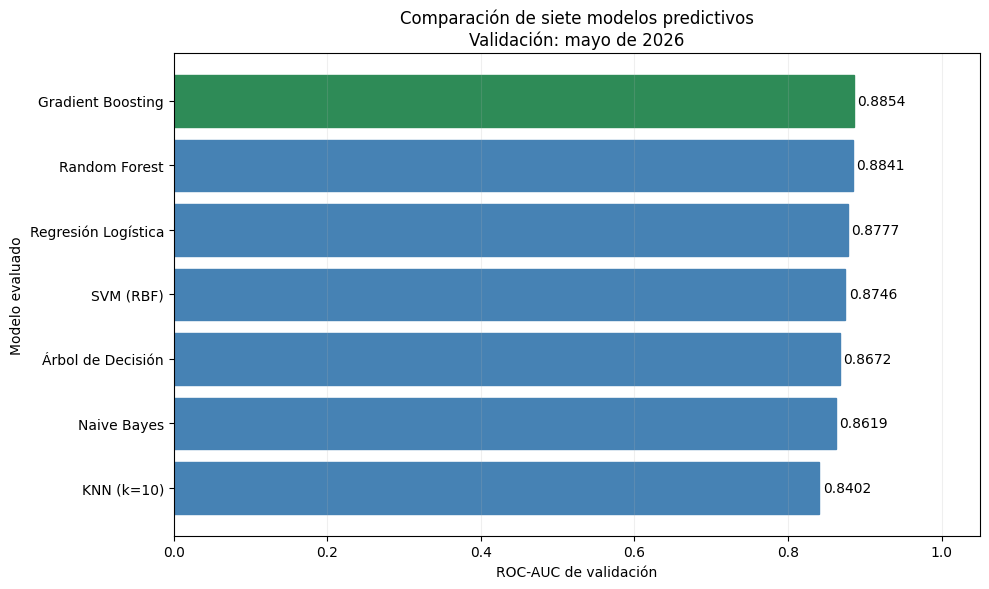

In [21]:

# ==================================================
# PASO 10.3. COMPARACIÓN GRÁFICA DE LOS SIETE MODELOS
# ==================================================

# Recuperar y ordenar resultados de mayo
datos_grafico = tabla_comparativa.sort_values(
    "ROC-AUC",
    ascending=True
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    datos_grafico["Modelo"],
    datos_grafico["ROC-AUC"]
)

# Destacar el modelo seleccionado
for barra, nombre in zip(
    barras,
    datos_grafico["Modelo"]
):
    if nombre == mejor_nombre:
        barra.set_color("seagreen")
    else:
        barra.set_color("steelblue")

# Colocar valor sobre cada barra
for i, valor in enumerate(datos_grafico["ROC-AUC"]):
    plt.text(
        valor + 0.005,
        i,
        f"{valor:.4f}",
        va="center"
    )

plt.xlim(0, 1.05)

plt.xlabel("ROC-AUC de validación")
plt.ylabel("Modelo evaluado")

plt.title(
    "Comparación de siete modelos predictivos\n"
    "Validación: mayo de 2026"
)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


In [22]:

# ==================================================
# PASO 11.1. DATOS PARA LOS KPI
# ==================================================

# Contar registros originales en SQL Server
with engine.connect() as conexion:
    registros_evaluados = conexion.execute(
        text("SELECT COUNT(*) FROM dbo.raw_cita")
    ).scalar_one()

# Registros que superaron la validación
registros_validados = len(df_modelo)

# Inasistencias del dataset validado
inasistencias = int(df_modelo[OBJETIVO].sum())

# Referencia básica: predecir siempre la clase
# más frecuente en el conjunto de entrenamiento
clase_mayoritaria = (
    train[OBJETIVO].value_counts().idxmax()
)

pred_baseline = np.full(
    len(y_test),
    clase_mayoritaria
)

baseline_accuracy = (
    accuracy_score(y_test, pred_baseline) * 100
)

mejora = accuracy_final * 100 - baseline_accuracy

print("DATOS PARA LOS KPI")
print("Registros evaluados:", registros_evaluados)
print("Registros validados:", registros_validados)
print("Inasistencias:", inasistencias)
print(f"Accuracy de referencia: {baseline_accuracy:.2f}%")
print(f"Mejora del modelo: {mejora:.2f} puntos porcentuales")


DATOS PARA LOS KPI
Registros evaluados: 10080
Registros validados: 8996
Inasistencias: 3381
Accuracy de referencia: 63.37%
Mejora del modelo: 19.78 puntos porcentuales


In [23]:

# ==================================================
# PASO 11.2. EVALUACIÓN DE LOS DIEZ KPI
# ==================================================

if registros_evaluados <= 0:
    raise ValueError("No hay registros originales.")

# Calcular los indicadores
kpi01 = 100 * registros_validados / registros_evaluados
kpi02 = 100 * inasistencias / registros_validados
kpi03 = 100 * vp / (vp + fn)
kpi04 = 100 * vp / (vp + fp)
kpi05 = 100 * (vp + vn) / (vp + vn + fp + fn)
kpi06 = 100 * fp / (fp + vn)
kpi07 = 100 * fn / (vp + fn)
kpi08 = 100 * f2_final
kpi09 = roc_auc_final
kpi10 = mejora

# Construir tabla de indicadores
datos_kpis = [
    ("KPI-01", "Porcentaje de registros validados",
     kpi01, "≥ 90%", kpi01 >= 90),

    ("KPI-02", "Tasa de inasistencia",
     kpi02, "Referencia: 15%", None),

    ("KPI-03", "Detección de inasistencia (Recall)",
     kpi03, "≥ 70%", kpi03 >= 70),

    ("KPI-04", "Precisión",
     kpi04, "≥ 80%", kpi04 >= 80),

    ("KPI-05", "Exactitud",
     kpi05, "≥ 80%", kpi05 >= 80),

    ("KPI-06", "Tasa de falsas alarmas",
     kpi06, "≤ 20%", kpi06 <= 20),

    ("KPI-07", "Inasistencias no detectadas",
     kpi07, "≤ 30%", kpi07 <= 30),

    ("KPI-08", "F2-Score",
     kpi08, "≥ 75%", kpi08 >= 75),

    ("KPI-09", "ROC-AUC",
     kpi09, "≥ 0.80", kpi09 >= 0.80),

    ("KPI-10", "Mejora frente a referencia básica",
     kpi10, "> 0 pp", kpi10 > 0),
]

filas = []

for codigo, nombre, valor, meta, cumple in datos_kpis:

    if cumple is None:
        estado = "REFERENCIA"
    elif cumple:
        estado = "CUMPLE"
    else:
        estado = "NO CUMPLE"

    if codigo == "KPI-09":
        resultado = f"{valor:.4f}"
    elif codigo == "KPI-10":
        resultado = f"{valor:+.2f} pp"
    else:
        resultado = f"{valor:.2f}%"

    filas.append({
        "Código": codigo,
        "KPI": nombre,
        "Resultado": resultado,
        "Meta": meta,
        "Estado": estado
    })

tabla_kpis = pd.DataFrame(filas)

print("=" * 65)
print("EVALUACIÓN DE LOS 10 KPI")
print("=" * 65)

display(tabla_kpis)

print("\nRESUMEN")
print(tabla_kpis["Estado"].value_counts().to_string())


EVALUACIÓN DE LOS 10 KPI


,Código,KPI,Resultado,Meta,Estado
0,KPI-01,Porcentaje de registros validados,89.25%,≥ 90%,NO CUMPLE
1,KPI-02,Tasa de inasistencia,37.58%,Referencia: 15%,REFERENCIA
2,KPI-03,Detección de inasistencia (Recall),71.76%,≥ 70%,CUMPLE
3,KPI-04,Precisión,80.16%,≥ 80%,CUMPLE
4,KPI-05,Exactitud,83.15%,≥ 80%,CUMPLE
5,KPI-06,Tasa de falsas alarmas,10.27%,≤ 20%,CUMPLE
6,KPI-07,Inasistencias no detectadas,28.24%,≤ 30%,CUMPLE
7,KPI-08,F2-Score,73.29%,≥ 75%,NO CUMPLE
8,KPI-09,ROC-AUC,0.8886,≥ 0.80,CUMPLE
9,KPI-10,Mejora frente a referencia básica,+19.78 pp,> 0 pp,CUMPLE



RESUMEN
Estado
CUMPLE        7
NO CUMPLE     2
REFERENCIA    1


In [24]:

# ==================================================
# PASO 12.1. GUARDAR EVIDENCIAS DEL PROYECTO
# ==================================================

from pathlib import Path

# Crear carpeta para los resultados de Jupyter
CARPETA_SALIDA = Path.cwd() / "resultados_jupyter"

CARPETA_SALIDA.mkdir(
    parents=True,
    exist_ok=True
)

# Guardar comparación de los siete modelos
tabla_comparativa.to_csv(
    CARPETA_SALIDA / "comparacion_7_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar tabla de los 10 KPI
tabla_kpis.to_csv(
    CARPETA_SALIDA / "evaluacion_10_kpi.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar métricas del modelo final
metricas_finales = pd.DataFrame([{
    "Modelo": mejor_nombre,
    "Citas evaluadas": len(y_test),
    "Accuracy (%)": accuracy_final * 100,
    "Precision (%)": precision_final * 100,
    "Recall (%)": recall_final * 100,
    "F1 (%)": f1_final * 100,
    "F2 (%)": f2_final * 100,
    "ROC-AUC": roc_auc_final,
    "PR-AUC": pr_auc_final,
    "VP": int(vp),
    "VN": int(vn),
    "FP": int(fp),
    "FN": int(fn)
}])

metricas_finales.to_csv(
    CARPETA_SALIDA / "resultados_gradient_boosting.csv",
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("EVIDENCIAS GUARDADAS CORRECTAMENTE")
print("=" * 60)

print("1. comparacion_7_modelos.csv")
print("2. evaluacion_10_kpi.csv")
print("3. resultados_gradient_boosting.csv")

print("\nUbicación:", CARPETA_SALIDA.resolve())


EVIDENCIAS GUARDADAS CORRECTAMENTE
1. comparacion_7_modelos.csv
2. evaluacion_10_kpi.csv
3. resultados_gradient_boosting.csv

Ubicación: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados_jupyter


In [2]:

# ==================================================
# RECUPERAR CONEXIÓN CON SQL SERVER
# ==================================================

import sys
from pathlib import Path

import pandas as pd
from sqlalchemy import text
from dotenv import load_dotenv

# Carpeta principal del proyecto
RUTA_PROYECTO = Path.cwd()

# Cargar configuración del proyecto
load_dotenv(RUTA_PROYECTO / ".env")

# Localizar el archivo database.py
RUTA_SRC = RUTA_PROYECTO / "src"

if str(RUTA_SRC) not in sys.path:
    sys.path.insert(0, str(RUTA_SRC))

# Importar conexión original
from database import engine_sqlserver

# Conectar con SQL Server
engine = engine_sqlserver()

with engine.connect() as conexion:
    nombre_bd = conexion.execute(
        text("SELECT DB_NAME()")
    ).scalar_one()

print("Conexión establecida correctamente.")
print("Base de datos:", nombre_bd)


Conexión establecida correctamente.
Base de datos: RedSaludCarazoDW_V2


In [3]:

# ==================================================
# PASO 13.1. CONTROL DE DISPONIBILIDAD DE DATOS
# ==================================================

print("=" * 65)
print("VALIDADOR DE CALIDAD - DISPONIBILIDAD TEMPORAL")
print("=" * 65)

# Verificar los años disponibles en los registros originales
consulta_raw = text("""
    SELECT
        YEAR(fecha_cita) AS anio,
        COUNT(*) AS registros_originales
    FROM dbo.raw_cita
    WHERE fecha_cita IS NOT NULL
    GROUP BY YEAR(fecha_cita)
    ORDER BY anio
""")

# Verificar los años disponibles en el dataset predictivo
consulta_predictiva = text("""
    SELECT
        YEAR(fecha_cita) AS anio,
        COUNT(*) AS registros_validados
    FROM dbo.dm_dataset_prediccion
    WHERE fecha_cita IS NOT NULL
    GROUP BY YEAR(fecha_cita)
    ORDER BY anio
""")

with engine.connect() as conexion:

    datos_raw = pd.read_sql_query(
        consulta_raw,
        conexion
    )

    datos_predictivos = pd.read_sql_query(
        consulta_predictiva,
        conexion
    )

print("\nREGISTROS ORIGINALES POR AÑO:")
display(datos_raw)

print("\nREGISTROS PREDICTIVOS POR AÑO:")
display(datos_predictivos)

print("\nVerificación de períodos completada.")


VALIDADOR DE CALIDAD - DISPONIBILIDAD TEMPORAL

REGISTROS ORIGINALES POR AÑO:


,anio,registros_originales
0,2026,10080



REGISTROS PREDICTIVOS POR AÑO:


,anio,registros_validados
0,2026,8996



Verificación de períodos completada.


In [4]:

# ==================================================
# PASO 13.2. VALIDAR AÑO SOLICITADO
# ==================================================

# Cambia el año para realizar distintas pruebas
ANIO_SOLICITADO = 2024

anios_disponibles = (
    datos_predictivos["anio"]
    .dropna()
    .astype(int)
    .tolist()
)

print("=" * 65)
print("CONTROL DE CALIDAD DEL PERÍODO SOLICITADO")
print("=" * 65)

print("Año solicitado:", ANIO_SOLICITADO)
print("Años disponibles:", anios_disponibles)

if ANIO_SOLICITADO not in anios_disponibles:

    print("\nHALLAZGO DE CALIDAD:")
    print("No existen registros predictivos")
    print("para el año solicitado.")

    print("\nACCIÓN RECOMENDADA:")
    print("Verificar si los datos históricos")
    print("fueron cargados al Data Warehouse.")

    print("\nESTADO: NO APTO PARA ANÁLISIS")
    periodo_valido = False

else:

    print("\nEl período solicitado tiene datos.")

    registros_periodo = datos_predictivos.loc[
        datos_predictivos["anio"] == ANIO_SOLICITADO,
        "registros_validados"
    ].sum()

    print("Registros disponibles:", registros_periodo)

    print("\nESTADO: PERÍODO DISPONIBLE")
    periodo_valido = True


CONTROL DE CALIDAD DEL PERÍODO SOLICITADO
Año solicitado: 2024
Años disponibles: [2026]

HALLAZGO DE CALIDAD:
No existen registros predictivos
para el año solicitado.

ACCIÓN RECOMENDADA:
Verificar si los datos históricos
fueron cargados al Data Warehouse.

ESTADO: NO APTO PARA ANÁLISIS


In [5]:

# ==================================================
# PASO 14. CONSULTAR DEFINICIÓN DEL DATASET PREDICTIVO
# ==================================================

from sqlalchemy import text

print("=" * 65)
print("REVISIÓN DE REGLAS Y TRANSFORMACIONES EN SQL SERVER")
print("=" * 65)

consulta = text("""
    SELECT
        OBJECT_DEFINITION(
            OBJECT_ID('dbo.dm_dataset_prediccion')
        ) AS definicion_sql
""")

with engine.connect() as conexion:
    resultado = conexion.execute(consulta).scalar_one()

if resultado is not None:
    print("\nDEFINICIÓN SQL ENCONTRADA:\n")
    print(resultado)
else:
    print("\nNo fue posible consultar la definición.")
    print("Debemos revisar los permisos o el tipo de objeto.")

print("\nConsulta finalizada.")


REVISIÓN DE REGLAS Y TRANSFORMACIONES EN SQL SERVER

No fue posible consultar la definición.
Debemos revisar los permisos o el tipo de objeto.

Consulta finalizada.


In [6]:

# ==================================================
# PASO 15. IDENTIFICAR OBJETOS DE SQL SERVER
# ==================================================

from sqlalchemy import text
import pandas as pd

print("=" * 65)
print("IDENTIFICACIÓN DE OBJETOS DEL DATA WAREHOUSE")
print("=" * 65)

consulta = text("""
    SELECT
        SCHEMA_NAME(o.schema_id) AS esquema,
        o.name AS nombre_objeto,
        o.type_desc AS tipo_objeto,
        o.create_date AS fecha_creacion,
        o.modify_date AS fecha_modificacion
    FROM sys.objects AS o
    WHERE o.name IN (
        'raw_cita',
        'dm_dataset_prediccion'
    )
    ORDER BY o.name
""")

with engine.connect() as conexion:
    objetos = pd.read_sql_query(
        consulta,
        conexion
    )

print("\nOBJETOS ENCONTRADOS:")
display(objetos)

print("\nRevisión completada.")


IDENTIFICACIÓN DE OBJETOS DEL DATA WAREHOUSE

OBJETOS ENCONTRADOS:


,esquema,nombre_objeto,tipo_objeto,fecha_creacion,fecha_modificacion
0,dbo,dm_dataset_prediccion,USER_TABLE,2026-09-27 18:36:01.637,2026-09-27 18:36:01.637
1,dbo,raw_cita,USER_TABLE,2026-09-27 18:18:06.080,2026-09-27 18:18:06.153



Revisión completada.


In [7]:

# ==================================================
# PASO 16. INSPECCIÓN DE ESTRUCTURA DE TABLAS
# CALIDAD, TRAZABILIDAD Y LINAJE DE DATOS
# ==================================================

from sqlalchemy import text
import pandas as pd

print("=" * 65)
print("ANÁLISIS DE ESTRUCTURA DEL DATA WAREHOUSE")
print("=" * 65)

consulta = text("""
    SELECT
        t.name AS tabla,
        c.column_id AS posicion,
        c.name AS columna,
        ty.name AS tipo_dato,
        c.is_nullable AS permite_nulos
    FROM sys.tables AS t
    INNER JOIN sys.schemas AS s
        ON t.schema_id = s.schema_id
    INNER JOIN sys.columns AS c
        ON t.object_id = c.object_id
    INNER JOIN sys.types AS ty
        ON c.user_type_id = ty.user_type_id
    WHERE s.name = 'dbo'
      AND t.name IN (
          'raw_cita',
          'dm_dataset_prediccion'
      )
    ORDER BY
        t.name,
        c.column_id
""")

with engine.connect() as conexion:
    estructura = pd.read_sql_query(
        consulta,
        conexion
    )

# Separar estructura de las dos tablas
estructura_raw = estructura[
    estructura["tabla"] == "raw_cita"
].copy()

estructura_predictiva = estructura[
    estructura["tabla"] == "dm_dataset_prediccion"
].copy()

print("\n1. TABLA DE REGISTROS ORIGINALES")
display(estructura_raw)

print("\n2. TABLA DEL DATASET PREDICTIVO")
display(estructura_predictiva)

print("\n3. RESUMEN")

print(
    "Columnas originales:",
    len(estructura_raw)
)

print(
    "Columnas predictivas:",
    len(estructura_predictiva)
)

print("\nInspección completada correctamente.")


ANÁLISIS DE ESTRUCTURA DEL DATA WAREHOUSE

1. TABLA DE REGISTROS ORIGINALES


,tabla,posicion,columna,tipo_dato,permite_nulos
13,raw_cita,1,id_raw,bigint,False
14,raw_cita,2,lote_carga,nvarchar,False
15,raw_cita,3,origen_dataset,nvarchar,False
16,raw_cita,4,id_cita,nvarchar,True
17,raw_cita,5,fecha_cita,date,True
18,raw_cita,6,centro_salud,nvarchar,True
19,raw_cita,7,canal_agendamiento,nvarchar,True
20,raw_cita,8,grupo_edad,nvarchar,True
21,raw_cita,9,especialidad,nvarchar,True
22,raw_cita,10,costo_estimado_usd,decimal,True



2. TABLA DEL DATASET PREDICTIVO


,tabla,posicion,columna,tipo_dato,permite_nulos
0,dm_dataset_prediccion,1,id_cita,nvarchar,False
1,dm_dataset_prediccion,2,fecha_cita,date,False
2,dm_dataset_prediccion,3,anio,int,False
3,dm_dataset_prediccion,4,mes,int,False
4,dm_dataset_prediccion,5,centro_salud,nvarchar,False
5,dm_dataset_prediccion,6,especialidad,nvarchar,False
6,dm_dataset_prediccion,7,canal_agendamiento,nvarchar,False
7,dm_dataset_prediccion,8,grupo_edad,nvarchar,False
8,dm_dataset_prediccion,9,tipo_cobertura,nvarchar,True
9,dm_dataset_prediccion,10,espera_dias,int,False



3. RESUMEN
Columnas originales: 19
Columnas predictivas: 13

Inspección completada correctamente.


In [8]:

# ==================================================
# PASO 17.1. TRAZABILIDAD DE ORIGEN Y LOTES DE CARGA
# ==================================================

consulta_lotes = text("""
    SELECT
        origen_dataset,
        lote_carga,
        COUNT(*) AS total_registros,
        COUNT(id_cita) AS ids_no_nulos,
        COUNT(DISTINCT id_cita) AS ids_distintos
    FROM dbo.raw_cita
    GROUP BY
        origen_dataset,
        lote_carga
    ORDER BY
        origen_dataset,
        lote_carga
""")

with engine.connect() as conexion:
    resumen_lotes = pd.read_sql_query(
        consulta_lotes,
        conexion
    )

print("=" * 65)
print("TRAZABILIDAD DE LOS DATOS ORIGINALES")
print("=" * 65)

display(resumen_lotes)

print("\nTotal de registros:")
print(resumen_lotes["total_registros"].sum())


TRAZABILIDAD DE LOS DATOS ORIGINALES


,origen_dataset,lote_carga,total_registros,ids_no_nulos,ids_distintos
0,ampliado,20260928T002744032220Z,10080,10080,10000



Total de registros:
10080


In [9]:

# ==================================================
# PASO 17.2. COMPARACIÓN DE IDENTIFICADORES
# ==================================================

consulta_raw_ids = text("""
    SELECT
        id_cita,
        origen_dataset,
        lote_carga
    FROM dbo.raw_cita
""")

consulta_dm_ids = text("""
    SELECT id_cita
    FROM dbo.dm_dataset_prediccion
""")

with engine.connect() as conexion:

    ids_raw = pd.read_sql_query(
        consulta_raw_ids,
        conexion
    )

    ids_dm = pd.read_sql_query(
        consulta_dm_ids,
        conexion
    )

# Normalizar identificadores únicamente para compararlos
def normalizar_id(serie):
    return serie.astype("string").str.strip().str.upper()

ids_raw["id_comparacion"] = normalizar_id(
    ids_raw["id_cita"]
)

ids_dm["id_comparacion"] = normalizar_id(
    ids_dm["id_cita"]
)

# Considerar vacíos como identificadores faltantes
ids_raw["id_comparacion"] = (
    ids_raw["id_comparacion"].replace("", pd.NA)
)

ids_dm["id_comparacion"] = (
    ids_dm["id_comparacion"].replace("", pd.NA)
)

# Identificadores disponibles en el dataset predictivo
conjunto_dm = set(
    ids_dm["id_comparacion"].dropna()
)

# Comprobar correspondencia con el dataset predictivo
ids_raw["existe_en_predictivo"] = (
    ids_raw["id_comparacion"].isin(conjunto_dm)
)

# Resumen por origen
resumen_origen = (
    ids_raw
    .groupby("origen_dataset", dropna=False)
    .agg(
        registros_originales=("id_cita", "size"),
        identificadores_faltantes=(
            "id_comparacion",
            lambda x: int(x.isna().sum())
        ),
        registros_con_id_en_predictivo=(
            "existe_en_predictivo",
            "sum"
        )
    )
    .reset_index()
)

resumen_origen["registros_sin_correspondencia"] = (
    resumen_origen["registros_originales"]
    - resumen_origen["registros_con_id_en_predictivo"]
)

print("=" * 65)
print("ANÁLISIS DE CORRESPONDENCIA DE REGISTROS")
print("=" * 65)

display(resumen_origen)

print("\nREGISTROS ORIGINALES:", len(ids_raw))
print("REGISTROS PREDICTIVOS:", len(ids_dm))

print(
    "Identificadores distintos en origen:",
    ids_raw["id_comparacion"].nunique()
)

print(
    "Identificadores distintos en predictivo:",
    ids_dm["id_comparacion"].nunique()
)

ids_raw_unicos = set(
    ids_raw["id_comparacion"].dropna()
)

print(
    "Identificadores predictivos sin correspondencia en origen:",
    len(conjunto_dm - ids_raw_unicos)
)

print("\nComparación finalizada.")


ANÁLISIS DE CORRESPONDENCIA DE REGISTROS


,origen_dataset,registros_originales,identificadores_faltantes,registros_con_id_en_predictivo,registros_sin_correspondencia
0,ampliado,10080,0,8996,1084



REGISTROS ORIGINALES: 10080
REGISTROS PREDICTIVOS: 8996
Identificadores distintos en origen: 10000
Identificadores distintos en predictivo: 8996
Identificadores predictivos sin correspondencia en origen: 0

Comparación finalizada.


In [10]:

# ==================================================
# PASO 18.2. EJECUTAR VALIDADOR DE CALIDAD
# ==================================================

import sys
from pathlib import Path

ruta_src = Path.cwd() / "src"

if str(ruta_src) not in sys.path:
    sys.path.insert(0, str(ruta_src))

from validador_calidad import validar_calidad

# Evaluar todos los períodos disponibles
resultado_calidad = validar_calidad()

print("\nTRES KPI DE CALIDAD")
display(resultado_calidad["indicadores"])

print("\nHALLAZGOS IDENTIFICADOS")
display(resultado_calidad["hallazgos"])

print("\nEVIDENCIA DE TRAZABILIDAD")
display(resultado_calidad["trazabilidad"])


RED SALUD INTEGRAL CARAZO
PIPELINE DE VALIDACIÓN DE CALIDAD

Período solicitado: Todos
Registros originales: 10080
Registros predictivos: 8996

Validación ejecutada.
Evidencias guardadas en: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados_jupyter

TRES KPI DE CALIDAD


,KPI,Resultado (%),Meta,Estado
0,Registros validados (PRV),89.25,>= 90%,NO CUMPLE
1,Completitud,90.87,Por definir,PROPUESTO
2,Validez lógica entre completos,99.97,Por definir,PROPUESTO



HALLAZGOS IDENTIFICADOS


,Hallazgo,Cantidad,Accion
0,Sin correspondencia predictiva,1084,Investigar reglas y causas de exclusión
1,Registros incompletos,920,Revisar los campos obligatorios
2,Registros completos con reglas inválidas,3,Revisar rangos y valores permitidos
3,Identificadores duplicados en origen,160,Revisar posibles duplicidades



EVIDENCIA DE TRAZABILIDAD


,fecha_ejecucion_utc,tabla_origen,tabla_predictiva,periodo_solicitado,registros_originales,registros_predictivos,registros_correspondientes
0,2026-10-16T21:12:00.036313+00:00,dbo.raw_cita,dbo.dm_dataset_prediccion,Todos,10080,8996,8996


In [11]:

# ============================================================
# PASO 19. DIAGNÓSTICO DE HALLAZGOS DE CALIDAD
# ============================================================

import pandas as pd
from sqlalchemy import text

from validador_calidad import (
    CAMPOS_OBLIGATORIOS,
    normalizar_ids
)

print("=" * 65)
print("DIAGNÓSTICO DE CALIDAD - RED SALUD INTEGRAL CARAZO")
print("=" * 65)

# ------------------------------------------------------------
# 1. CONSULTAR LOS REGISTROS ORIGINALES
# ------------------------------------------------------------

with engine.connect() as conexion:
    raw_diagnostico = pd.read_sql_query(
        text("SELECT * FROM dbo.raw_cita"),
        conexion
    )

print("\nRegistros revisados:", len(raw_diagnostico))

# ------------------------------------------------------------
# 2. IDENTIFICAR VALORES FALTANTES POR COLUMNA
# ------------------------------------------------------------

resultado_campos = []

for columna in CAMPOS_OBLIGATORIOS:

    serie = raw_diagnostico[columna]

    # Detectar valores nulos
    faltante = serie.isna()

    # Detectar cadenas vacías o espacios en blanco
    if (
        pd.api.types.is_object_dtype(serie)
        or pd.api.types.is_string_dtype(serie)
    ):
        vacio = (
            serie.astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        )

        faltante = faltante | vacio

    cantidad = int(faltante.sum())

    resultado_campos.append({
        "Campo": columna,
        "Registros con valor faltante": cantidad,
        "Porcentaje (%)": round(
            100 * cantidad / len(raw_diagnostico), 2
        )
    })

tabla_faltantes = pd.DataFrame(resultado_campos)

tabla_faltantes = tabla_faltantes.sort_values(
    "Registros con valor faltante",
    ascending=False
)

print("\n1. VALORES FALTANTES POR CAMPO")
display(tabla_faltantes)

# ------------------------------------------------------------
# 3. COMPROBAR IDENTIFICADORES REPETIDOS
# ------------------------------------------------------------

ids_originales = (
    raw_diagnostico["id_cita"]
    .astype("string")
)

ids_normalizados = normalizar_ids(
    raw_diagnostico["id_cita"]
)

repetidos_originales = int(
    ids_originales.dropna()
    .loc[lambda x: x.str.strip().ne("")]
    .duplicated(keep=False)
    .sum()
)

repetidos_normalizados = int(
    ids_normalizados.dropna()
    .duplicated(keep=False)
    .sum()
)

print("\n2. VERIFICACIÓN DE IDENTIFICADORES")

print(
    "Filas con ID exactamente repetido:",
    repetidos_originales
)

print(
    "Filas con ID repetido después de normalizar:",
    repetidos_normalizados
)

print("\nDiagnóstico finalizado.")
print("No se modificaron los datos de SQL Server.")


DIAGNÓSTICO DE CALIDAD - RED SALUD INTEGRAL CARAZO

Registros revisados: 10080

1. VALORES FALTANTES POR CAMPO


,Campo,Registros con valor faltante,Porcentaje (%)
3,especialidad,120,1.19
2,centro_salud,120,1.19
6,espera_dias,120,1.19
7,citas_previas_perdidas,120,1.19
4,canal_agendamiento,120,1.19
5,grupo_edad,120,1.19
8,recordatorios_enviados,120,1.19
9,no_asistio,80,0.79
1,fecha_cita,0,0.00
0,id_cita,0,0.00



2. VERIFICACIÓN DE IDENTIFICADORES
Filas con ID exactamente repetido: 160
Filas con ID repetido después de normalizar: 160

Diagnóstico finalizado.
No se modificaron los datos de SQL Server.


In [12]:

# ============================================================
# PASO 20. VERIFICACIÓN DE IDENTIFICADORES DUPLICADOS
# SQL SERVER VS PYTHON
# ============================================================

consulta_duplicados = text("""
    WITH duplicados AS (
        SELECT
            id_cita,
            COUNT(*) AS cantidad
        FROM dbo.raw_cita
        WHERE id_cita IS NOT NULL
        GROUP BY id_cita
        HAVING COUNT(*) > 1
    )
    SELECT
        (SELECT COUNT(*)
         FROM dbo.raw_cita) AS total_registros,

        (SELECT COUNT(DISTINCT id_cita)
         FROM dbo.raw_cita) AS ids_distintos,

        (SELECT COUNT(*)
         FROM duplicados) AS grupos_repetidos,

        (SELECT COALESCE(SUM(cantidad), 0)
         FROM duplicados) AS filas_en_grupos_repetidos,

        (SELECT COALESCE(SUM(cantidad - 1), 0)
         FROM duplicados) AS filas_adicionales
""")

with engine.connect() as conexion:
    verificacion_sql = pd.read_sql_query(
        consulta_duplicados,
        conexion
    )

# Comparación con el diagnóstico de Python
ids_python = (
    raw_diagnostico["id_cita"]
    .astype("string")
)

resumen_python = pd.DataFrame([{
    "total_registros": len(raw_diagnostico),
    "ids_distintos": ids_python.nunique(),
    "filas_en_grupos_repetidos": int(
        ids_python.dropna()
        .duplicated(keep=False)
        .sum()
    )
}])

print("=" * 65)
print("VERIFICACIÓN DE DUPLICIDAD")
print("=" * 65)

print("\n1. RESULTADO DE SQL SERVER")
display(verificacion_sql)

print("\n2. RESULTADO DE PYTHON")
display(resumen_python)

# Comprobar si coinciden
coinciden = (
    int(verificacion_sql.iloc[0]["ids_distintos"])
    == int(resumen_python.iloc[0]["ids_distintos"])
)

if coinciden:
    print("\nVERIFICACIÓN: Los conteos coinciden.")
else:
    print("\nADVERTENCIA:")
    print("SQL Server y Python muestran conteos distintos.")
    print("Es necesario investigar antes de concluir.")

print("\nNo se modificaron registros.")


VERIFICACIÓN DE DUPLICIDAD

1. RESULTADO DE SQL SERVER


,total_registros,ids_distintos,grupos_repetidos,filas_en_grupos_repetidos,filas_adicionales
0,10080,10000,80,160,80



2. RESULTADO DE PYTHON


,total_registros,ids_distintos,filas_en_grupos_repetidos
0,10080,10000,160



VERIFICACIÓN: Los conteos coinciden.

No se modificaron registros.


In [13]:

# ============================================================
# PASO 21.1. GESTIÓN DE HALLAZGOS MEDIANTE PHVA
# ============================================================

from datetime import datetime, timezone
from pathlib import Path
import pandas as pd

# Recuperar cantidades calculadas por el validador
hallazgos = resultado_calidad["hallazgos"].set_index(
    "Hallazgo"
)

incompletos = int(
    hallazgos.loc[
        "Registros incompletos", "Cantidad"
    ]
)

invalidos = int(
    hallazgos.loc[
        "Registros completos con reglas inválidas",
        "Cantidad"
    ]
)

sin_correspondencia = int(
    hallazgos.loc[
        "Sin correspondencia predictiva", "Cantidad"
    ]
)

# Recuperar la comprobación de SQL Server
grupos_duplicados = int(
    verificacion_sql.iloc[0]["grupos_repetidos"]
)

filas_adicionales = int(
    verificacion_sql.iloc[0]["filas_adicionales"]
)

fecha_revision = datetime.now(
    timezone.utc
).isoformat()

# Registro de acciones propuestas
acciones_phva = pd.DataFrame([
    {
        "Codigo": "H01",
        "Hallazgo": "Registros incompletos",
        "Cantidad": incompletos,
        "Politica": "POL-02 Completitud",
        "Accion_propuesta":
            "Revisar los campos faltantes y su captura",
        "Responsable_propuesto": "Admisión y TI",
        "Estado": "PENDIENTE",
        "Verificacion":
            "Recalcular el KPI de completitud"
    },
    {
        "Codigo": "H02",
        "Hallazgo": "Valores lógicos inválidos",
        "Cantidad": invalidos,
        "Politica": "POL-05 Valores anómalos",
        "Accion_propuesta":
            "Revisar los registros y las reglas incumplidas",
        "Responsable_propuesto": "TI",
        "Estado": "PENDIENTE",
        "Verificacion":
            "Repetir las validaciones de rangos y valores"
    },
    {
        "Codigo": "H03",
        "Hallazgo": "Identificadores repetidos",
        "Cantidad": grupos_duplicados,
        "Politica": "POL-04 Duplicidad",
        "Accion_propuesta":
            "Comprobar los grupos repetidos antes de corregir",
        "Responsable_propuesto": "TI",
        "Estado": "PENDIENTE",
        "Verificacion":
            "Repetir el control de unicidad"
    },
    {
        "Codigo": "H04",
        "Hallazgo": "Sin correspondencia predictiva",
        "Cantidad": sin_correspondencia,
        "Politica": "Revisión de reglas y linaje",
        "Accion_propuesta":
            "Investigar por qué no aparecen en el dataset",
        "Responsable_propuesto": "TI y calidad",
        "Estado": "PENDIENTE",
        "Verificacion":
            "Comparar nuevamente origen y destino"
    }
])

acciones_phva["Fecha_revision_UTC"] = fecha_revision

print("=" * 65)
print("GESTIÓN DE HALLAZGOS - CICLO PHVA")
print("=" * 65)

display(acciones_phva)

print("\nIdentificadores repetidos:", grupos_duplicados)
print("Filas adicionales por repetición:", filas_adicionales)
print("Acciones propuestas:", len(acciones_phva))
print("Estado inicial: PENDIENTE")


GESTIÓN DE HALLAZGOS - CICLO PHVA


,Codigo,Hallazgo,Cantidad,Politica,Accion_propuesta,Responsable_propuesto,Estado,Verificacion,Fecha_revision_UTC
0,H01,Registros incompletos,920,POL-02 Completitud,Revisar los campos faltantes y su captura,Admisión y TI,PENDIENTE,Recalcular el KPI de completitud,2026-10-16T21:21:27.618461+00:00
1,H02,Valores lógicos inválidos,3,POL-05 Valores anómalos,Revisar los registros y las reglas incumplidas,TI,PENDIENTE,Repetir las validaciones de rangos y valores,2026-10-16T21:21:27.618461+00:00
2,H03,Identificadores repetidos,80,POL-04 Duplicidad,Comprobar los grupos repetidos antes de corregir,TI,PENDIENTE,Repetir el control de unicidad,2026-10-16T21:21:27.618461+00:00
3,H04,Sin correspondencia predictiva,1084,Revisión de reglas y linaje,Investigar por qué no aparecen en el dataset,TI y calidad,PENDIENTE,Comparar nuevamente origen y destino,2026-10-16T21:21:27.618461+00:00



Identificadores repetidos: 80
Filas adicionales por repetición: 80
Acciones propuestas: 4
Estado inicial: PENDIENTE


In [14]:

# ============================================================
# PASO 21.2. GUARDAR EVIDENCIA DE GESTIÓN DE CALIDAD
# ============================================================

carpeta_salida = Path.cwd() / "resultados_jupyter"

carpeta_salida.mkdir(
    parents=True,
    exist_ok=True
)

ruta_archivo = (
    carpeta_salida / "registro_acciones_phva.csv"
)

acciones_phva.to_csv(
    ruta_archivo,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 65)
print("EVIDENCIA PHVA GUARDADA")
print("=" * 65)

print("Archivo:", ruta_archivo.resolve())
print("Hallazgos registrados:", len(acciones_phva))
print("No se modificaron datos de SQL Server.")


EVIDENCIA PHVA GUARDADA
Archivo: C:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados_jupyter\registro_acciones_phva.csv
Hallazgos registrados: 4
No se modificaron datos de SQL Server.


In [15]:

# ==================================================
# PASO 22.2. DEMOSTRACIÓN DEL CONTROL DE CALIDAD
# ==================================================

import importlib
import validador_calidad

# Recargar el módulo porque lo acabamos de modificar
importlib.reload(validador_calidad)

verificar_periodo_mineria = (
    validador_calidad.verificar_periodo_mineria
)

# PRUEBA 1: Solicitar registros de 2024
print("\nPRUEBA 1 - AÑO 2024")

control_2024 = verificar_periodo_mineria(2024)

print("\n" + "-" * 65)

# PRUEBA 2: Solicitar registros de 2026
print("\nPRUEBA 2 - AÑO 2026")

control_2026 = verificar_periodo_mineria(2026)



PRUEBA 1 - AÑO 2024
CONTROL DE CALIDAD ANTES DEL ENTRENAMIENTO

Año solicitado: 2024
Registros disponibles: 0

PARTICIÓN TEMPORAL
Entrenamiento: 0
Validación: 0
Prueba: 0

ESTADO: NO APTO PARA ENTRENAMIENTO
- No existen registros predictivos para el año solicitado.

-----------------------------------------------------------------

PRUEBA 2 - AÑO 2026
CONTROL DE CALIDAD ANTES DEL ENTRENAMIENTO

Año solicitado: 2026
Registros disponibles: 8996

PARTICIÓN TEMPORAL
Entrenamiento: 5948
Validación: 1511
Prueba: 1537

ESTADO: APTO PARA ENTRENAMIENTO
Las comprobaciones esenciales se superaron.
